# <font color='#BFD72F' size=6>**0. Imports**</font> <a class="anchor" id="1"></a>

[Back to TOC](#toc)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import seaborn as sns


from config import (
    WEATHER_COLUMNS,
    MONTH_TO_SEASON,
    PROCESSED_DIR,
    WARMUP_END,
    WARMUP_START,
    HOT_PERCENTILE,
    PREPROCESSED_DIR

)

from preprocessing_functions import (
    audit_weather_data,
    get_model_ready_data,
    estimate_threshold_incrementally,
    estimate_threshold_hourly,
    estimate_threshold_daily_max,
    get_pooled_hourly_warmup,
    label_stream_online,
    label_heat_stress_hour,
    plot_heatwave_detection,
    plot_calendar_heatmap,
    plot_event_comparison,
    prepare_stream_features
)

In [2]:
# Load the raw weather data for each city
weather_data = {
    city_name: pd.read_csv(
        PROCESSED_DIR / f"{city_name.lower()}.csv",
        parse_dates=["time"],
    )
    for city_name in ["Aveiro", "Viseu"]
}

df_aveiro_raw = weather_data["Aveiro"]
df_viseu_raw = weather_data["Viseu"]


# <font color='#BFD72F' size=6>**3. Data Preprocessing**</font> <a class="anchor" id="1"></a>

- 3.1 **Duplicates:** Removed, kept first observation chronologically
- 3.2 **Invalid values:** Replace with missing value (NaN)
- 3.3 **Missing Values:** Use foward-fill
- 3.4 **Missing timestamps:** Fail loudly


[Back to TOC](#toc)

In [3]:
clean_data = {}
audit_tables = []

for city_name, df in weather_data.items():
    clean_data[city_name], audit = audit_weather_data(
        df,
        city_name,
    )

    audit_tables.append(audit)

audit_summary = pd.concat(
    audit_tables,
    ignore_index=True,
)

display(audit_summary)

,city,issue,variable,count
0,Aveiro,Missing hourly timestamps,time,0
1,Viseu,Missing hourly timestamps,time,0


In [4]:
for city_name, df in clean_data.items():
    print(f"\n{'=' * 50}")
    print(city_name)
    print(f"{'=' * 50}")

    print(f"Rows: {len(df):,}")
    print(
        f"Period: {df['time'].min()} "
        f"to {df['time'].max()}"
    )

    print("\nMissing values:")
    display(
        df[WEATHER_COLUMNS]
        .isna()
        .sum()
        .to_frame("missing")
    )

    print("\nDescriptive statistics:")
    display(df[WEATHER_COLUMNS].describe().round(2))


Aveiro
Rows: 96,408
Period: 2013-01-01 00:00:00 to 2023-12-31 23:00:00

Missing values:


,missing
temperature,0
relative_humidity,0
precipitation,0
wind_speed,0
night_min_temperature,0



Descriptive statistics:


,temperature,relative_humidity,precipitation,wind_speed,night_min_temperature
count,96408.00,96408.00,96408.00,96408.00,96408.00
mean,15.62,79.15,0.13,14.44,12.77
std,5.18,16.07,0.51,7.94,4.22
min,-1.50,13.00,0.00,0.00,-0.50
25%,12.20,69.00,0.00,8.20,9.70
50%,15.50,83.00,0.00,13.40,13.20
75%,18.80,92.00,0.00,19.50,16.10
max,38.80,100.00,15.50,62.70,27.70



Viseu
Rows: 96,408
Period: 2013-01-01 00:00:00 to 2023-12-31 23:00:00

Missing values:


,missing
temperature,0
relative_humidity,0
precipitation,0
wind_speed,0
night_min_temperature,0



Descriptive statistics:


,temperature,relative_humidity,precipitation,wind_speed,night_min_temperature
count,96408.00,96408.00,96408.00,96408.00,96408.00
mean,14.24,73.28,0.13,10.03,10.38
std,7.15,21.08,0.51,5.71,5.26
min,-3.40,8.00,0.00,0.00,-3.40
25%,9.00,58.00,0.00,5.70,6.40
50%,13.30,78.00,0.00,8.80,10.30
75%,18.70,92.00,0.00,13.50,14.40
max,40.20,100.00,12.70,45.00,28.50


> Problem: Missing timestamps are not fixed <br>
> **Solution: Fail loudly missing timestamps**

> Problem: Changes are not being documented <br>
> **Solution: Instead of counts, document also changes** 

> Problem: Imputation of missing values <br>
> **Solution: Use only past values** 

In [5]:
clean_data = {
    city: get_model_ready_data(df, city_name=city)
    for city, df in clean_data.items()
}


Aveiro: Model-ready data
Rows retained: 96,408
Missing values imputed: 0

Viseu: Model-ready data
Rows retained: 96,408
Missing values imputed: 0


# <font color='#BFD72F' size=6>**4. Temperature Threshold**</font> <a class="anchor" id="1"></a>

- 4.1 **Warm-up Period:** 1 January 2013 – 31 December 2015.
- 4.2 **Quantile estimator:** River incrementally estimates the 80th-percentile threshold using one hourly temperature observation at a time.
- 4.3 **Frozen threshold:** The threshold is estimated exclusively from warm-up data and remains unchanged during evaluation (2016–2023).


[Back to TOC](#toc)

In [6]:
warmup_ends = {
    city: WARMUP_END
    for city in clean_data
}

print("Warm-up period:")
print(f"Start: {WARMUP_START.date()}")
print(f"End:   {WARMUP_END.date()}")

# Estimate the 80th-percentile threshold incrementally
# using hourly temperature observations from the warm-up period.
TAU_T_HOT, N_WARMUP_OBSERVATIONS = estimate_threshold_incrementally(
    clean_data,
    warmup_ends,
)

print(f"\nFrozen hot-temperature threshold: {TAU_T_HOT:.2f} °C")
print(f"Warm-up hourly observations processed: {N_WARMUP_OBSERVATIONS:,}")

Warm-up period:
Start: 2013-01-01
End:   2015-12-31

Frozen hot-temperature threshold: 20.21 °C
Warm-up hourly observations processed: 52,560


One important distinction for your report: 20.21 °C is the hourly hot-temperature threshold, not the heatwave definition itself. If your project defines a heatwave as at least three consecutive hot days, that needs a separate daily aggregation and event-detection step.

<span style="color: red;">TODO: Give only daily maximum or all values? </span>

> Daily maxima vs. the handbook definition. The handbook defines τ_T,hot = Q0.80(T) over the pooled warm-up temperature observations, and the event is y_t = 1 if T_t ≥ τ_T,hot. Your stream is hourly, so the target compares an hourly T_t to the threshold. A quantile of daily maxima will be noticeably higher than the 80th percentile of hourly values. The event would then occur well under 20% of the time, and the two cities’ event frequencies would not mean what the handbook intends. Unless your instructor approved a “hot-day” variant, I’d compute the quantile over all hourly warm-up temperatures.

In [7]:
# ============================================================
# 1. DEFINE THE WARM-UP PERIOD
# ============================================================

# Use the same fixed warm-up end date as the previous section.
warmup_ends = {
    city: WARMUP_END
    for city in clean_data
}

print("Warm-up end dates:")

for city, date in warmup_ends.items():
    print(f"{city}: {date.date()}")


# ============================================================
# 2. ESTIMATE THE THRESHOLDS
# ============================================================

# A: Pooled daily maxima (online estimate).
# This is included for comparison only.
TAU_DAILY_MAX, N_DAILY = estimate_threshold_daily_max(
    clean_data,
    warmup_ends,
)

# B: Pooled hourly temperatures (online estimate).
# This matches the handbook's hourly temperature definition.
TAU_HOURLY, N_HOURLY = estimate_threshold_hourly(
    clean_data,
    warmup_ends,
)

# C: Pooled hourly temperatures (exact NumPy quantile).
# This provides a reference against which to check River's estimate.
pooled_hourly_warmup = get_pooled_hourly_warmup(
    clean_data,
    warmup_ends,
)

TAU_HOURLY_EXACT = float(
    np.quantile(
        pooled_hourly_warmup,
        HOT_PERCENTILE,
    )
)

N_HOURLY_EXACT = len(pooled_hourly_warmup)


# ============================================================
# 3. VALIDATE THE OBSERVATION COUNTS
# ============================================================

print("\n=== Observation count validation ===")

print(f"Daily maxima processed:          {N_DAILY:,}")
print(f"Hourly observations (online):     {N_HOURLY:,}")
print(f"Hourly observations (exact):      {N_HOURLY_EXACT:,}")

if N_HOURLY != N_HOURLY_EXACT:
    print(
        "WARNING: The online and exact methods processed different "
        "numbers of hourly observations. Check the helper functions."
    )

if N_HOURLY_EXACT != len(pooled_hourly_warmup):
    raise AssertionError(
        "The exact hourly observation count is inconsistent."
    )


# ============================================================
# 4. COMPARE THE THRESHOLD ESTIMATES
# ============================================================

threshold_comparison = pd.DataFrame(
    {
        "threshold_C": [
            TAU_DAILY_MAX,
            TAU_HOURLY,
            TAU_HOURLY_EXACT,
        ],
        "n_values_used": [
            N_DAILY,
            N_HOURLY,
            N_HOURLY_EXACT,
        ],
    },
    index=[
        "A: daily maxima (online)",
        "B: hourly temperatures (online)",
        "B: hourly temperatures (exact NumPy)",
    ],
)

print("\n=== Threshold comparison ===")
display(threshold_comparison.round(3))

print(
    "\nDifference between daily-max and hourly online thresholds: "
    f"{TAU_DAILY_MAX - TAU_HOURLY:+.3f} °C"
)

print(
    "Difference between hourly online and exact thresholds: "
    f"{TAU_HOURLY - TAU_HOURLY_EXACT:+.3f} °C"
)


# ============================================================
# 5. FREEZE THE HANDBOOK'S HOURLY THRESHOLD
# ============================================================

# Keep the online hourly threshold for downstream use.
# Only accept it once the observation count has been validated.
if N_HOURLY != N_HOURLY_EXACT:
    raise ValueError(
        "Cannot validate the online hourly threshold: "
        "the online and exact observation counts differ."
    )

TAU_T_HOT = TAU_HOURLY
N_WARMUP_OBS = N_HOURLY

print(f"\nFrozen hot-temperature threshold: {TAU_T_HOT:.2f} °C")
print(f"Warm-up hourly observations processed: {N_WARMUP_OBS:,}")


# ============================================================
# 6. CALCULATE EVENT FREQUENCIES
# ============================================================

rows = []

for city, df in clean_data.items():

    timestamps = pd.to_datetime(df["time"])
    temperatures = pd.to_numeric(
        df["temperature"],
        errors="coerce",
    )

    # Include the entire warm-up end date.
    is_warmup = (
        (timestamps >= WARMUP_START)
        & (timestamps < WARMUP_END + pd.Timedelta(days=1))
    )

    is_evaluation = timestamps >= (
        WARMUP_END + pd.Timedelta(days=1)
    )

    for period, mask in [
        ("warm-up", is_warmup),
        ("evaluation", is_evaluation),
    ]:

        temps = temperatures.loc[mask]

        # Exclude missing and non-finite values from the denominator.
        temps = temps[np.isfinite(temps)]

        valid_hours = len(temps)

        rows.append(
            {
                "city": city,
                "period": period,
                "valid_hours": valid_hours,

                # Comparison only: daily-max threshold applied
                # to hourly temperatures.
                "event_rate_A_daily_max_%": (
                    100 * (temps >= TAU_DAILY_MAX).mean()
                    if valid_hours else np.nan
                ),

                # Handbook-aligned hourly temperature threshold.
                "event_rate_B_hourly_%": (
                    100 * (temps >= TAU_T_HOT).mean()
                    if valid_hours else np.nan
                ),
            }
        )

event_frequency = pd.DataFrame(rows)

print("\n=== Event frequency (% of valid hourly temperatures flagged) ===")
display(event_frequency.round(2))

print(
    f"\nFrozen hourly threshold used downstream: "
    f"{TAU_T_HOT:.2f} °C"
)

Warm-up end dates:
Aveiro: 2015-12-31
Viseu: 2015-12-31

=== Observation count validation ===
Daily maxima processed:          2,190
Hourly observations (online):     52,560
Hourly observations (exact):      52,560

=== Threshold comparison ===


,threshold_C,n_values_used
A: daily maxima (online),25.821,2190
B: hourly temperatures (online),20.211,52560
B: hourly temperatures (exact NumPy),20.100,52560



Difference between daily-max and hourly online thresholds: +5.610 °C
Difference between hourly online and exact thresholds: +0.111 °C

Frozen hot-temperature threshold: 20.21 °C
Warm-up hourly observations processed: 52,560

=== Event frequency (% of valid hourly temperatures flagged) ===


,city,period,valid_hours,event_rate_A_daily_max_%,event_rate_B_hourly_%
0,Aveiro,warm-up,26280,5.50,20.89
1,Aveiro,evaluation,70128,2.36,15.63
2,Viseu,warm-up,26280,6.29,17.77
3,Viseu,evaluation,70128,8.03,20.66



Frozen hourly threshold used downstream: 20.21 °C


### Key Conclusions

- **Hourly threshold selection:** The hourly River estimate was 20.21 °C, close to the exact NumPy 80th percentile of 20.10 °C. The daily-maximum threshold was higher at 25.82 °C, supporting the distinction between hourly and daily-maximum temperature definitions.

- **Differences between cities:** During evaluation (2016–2023), 15.63% of valid hourly temperatures in Aveiro and 20.66% in Viseu were at or above the frozen hourly threshold. Viseu therefore had a higher observed hourly event frequency during this period.

- **Changes between periods:** Aveiro's hourly event frequency decreased from 20.89% during warm-up to 15.63% during evaluation, while Viseu's increased from 17.77% to 20.66%. These are descriptive differences and do not, by themselves, establish their causes or statistical significance.

# <font color='#BFD72F' size=6>**5. Target Variable**</font> <a class="anchor" id="1"></a>

- **Hot Day:** Defined if maximum temperature reaches or exceeds threshold of the warmup
- **Consecutive hot days:** Minimum of 3 (parameter)
    - 1 hot day: No heatwave alert.
    - 2 consecutive hot days: No heatwave alert.
    - 3 consecutive hot days: The heatwave alert becomes active.
    - A subsequent hot day: The alert remains active.
    - A non-hot day: The alert becomes inactive, and the consecutive-day count resets.

- **Final Target:** if Heatwave is active

[Back to TOC](#toc)

In [8]:

labeled_data = {}

for city, df in clean_data.items():
    labeled_data[city] = label_stream_online(
        df,
        threshold=TAU_T_HOT,
        warmup_end=warmup_ends[city],
    )

    result = labeled_data[city]

    print(f"\n{'=' * 45}")
    print(city)
    print(f"{'=' * 45}")

    print("\nHourly target distribution:")
    display(
        result["target"]
        .value_counts()
        .sort_index()
        .rename_axis("target")
        .to_frame("hours")
    )

    print(
        f"Detected-alert hours: "
        f"{result['target'].sum():,}"
    )

    print(
        f"Evaluation period: "
        f"{result['time'].min()} to {result['time'].max()}"
    )



Aveiro

Hourly target distribution:


,hours
target,
0,46800
1,23328


Detected-alert hours: 23,328
Evaluation period: 2016-01-01 00:00:00 to 2023-12-31 23:00:00

Viseu

Hourly target distribution:


,hours
target,
0,43848
1,26280


Detected-alert hours: 26,280
Evaluation period: 2016-01-01 00:00:00 to 2023-12-31 23:00:00


> Problem: The alert only turns on from the first hour of the day after the third hot day completes. The third hot day itself is not labeled

1. This is not the T2 target in the handbook. The handbook defines y_t = 1 if the hourly T_t ≥ τ. Here the target is “3+ consecutive hot days”, which is a different event

2. The threshold and the detector can clash. The detector compares a daily maximum to threshold. That matched your original daily-maxima threshold. If you switch TAU_T_HOT to the hourly 80th percentile, almost every day’s maximum will exceed it, so hot days and alerts become very frequent.

3. The labels are delayed, which makes them a persistent state. 

3.1. The alert only turns on from the first hour of the day after the third hot day completes. The third hot day itself is not labeled.

3.2. Once on, it stays on through the next day, even if that day is cool, and only switches off when that day is finished.

3.3.The label for hour t depends only on days before day t, not on the current temperature, so there is no direct leakage. But the target is now very persistent (long runs of 1s and 0s). A model can score well just by predicting “same as before”, so check Recall and Macro-F1, not only Accuracy.

In [9]:
labeled_data = {}

for city, df in clean_data.items():
    result = label_heat_stress_hour(
        df,
        threshold=TAU_T_HOT,
        warmup_end=warmup_ends[city],
    )

    labeled_data[city] = result

    print(f"\n{'=' * 50}")
    print(city)
    print("=" * 50)

    for target in ["target_hot"]:
        valid = result[target].dropna()

        print(f"\n{target}:")
        display(
            valid.value_counts()
            .sort_index()
            .rename_axis("Class")
            .to_frame("Hourly observations")
        )

        print(f"Valid observations: {len(valid):,}")
        print(f"Positive observations: {(valid == 1).sum():,}")
        print(
            f"Positive percentage: "
            f"{100 * (valid == 1).mean():.2f}%"
            if len(valid) > 0
            else "Positive percentage: N/A"
        )


Aveiro

target_hot:


,Hourly observations
Class,
0.0,59164
1.0,10964


Valid observations: 70,128
Positive observations: 10,964
Positive percentage: 15.63%

Viseu

target_hot:


,Hourly observations
Class,
0.0,55638
1.0,14490


Valid observations: 70,128
Positive observations: 14,490
Positive percentage: 20.66%


### Visualize detector output

In [10]:
def plot_target_distribution(
    labeled_data: dict,
    warmup_end: str,
):
    """
    Visualize both target distributions for each district:
    - target_hot: individual hot days
    - target_heatwave: heatwave active after 3 consecutive hot days
    """

    cities = list(labeled_data.keys())

    fig, axes = plt.subplots(
        len(cities),
        2,
        figsize=(15, 5 * len(cities)),
        squeeze=False,
    )

    target_columns = [
        ("target_hot", "Hot Days"),
        ("target_heatwave", "Heatwave Alerts"),
    ]

    summaries = []

    for row, city in enumerate(cities):
        df = labeled_data[city].copy()
        df["time"] = pd.to_datetime(df["time"])

        # Exclude warm-up period from visualization and evaluation
        evaluation = df[df["time"] > pd.Timestamp(warmup_end)].copy()

        for col, (target, title) in enumerate(target_columns):
            ax = axes[row, col]

            daily_target = (
                evaluation.assign(
                    date=evaluation["time"].dt.normalize()
                )
                .groupby("date")[target]
                .first()
            )

            daily_target = daily_target.dropna()

            counts = daily_target.value_counts().reindex(
                [0, 1], fill_value=0
            )

            ax.bar(
                ["Not active", "Active"],
                counts.values,
            )

            ax.set_title(f"{city} — {title}")
            ax.set_ylabel("Number of days")
            ax.grid(axis="y", alpha=0.3)

            total = counts.sum()
            positive = counts.get(1, 0)

            summaries.append({
                "District": city,
                "Target": target,
                "Valid days": total,
                "Positive days": positive,
                "Negative days": counts.get(0, 0),
                "Positive (%)": (
                    100 * positive / total if total else np.nan
                ),
            })

            for i, value in enumerate(counts.values):
                ax.text(
                    i,
                    value,
                    str(value),
                    ha="center",
                    va="bottom",
                )

    plt.tight_layout()
    plt.show()

    target_summary = pd.DataFrame(summaries)

    return fig, target_summary

KeyError: 'Column not found: target_heatwave'

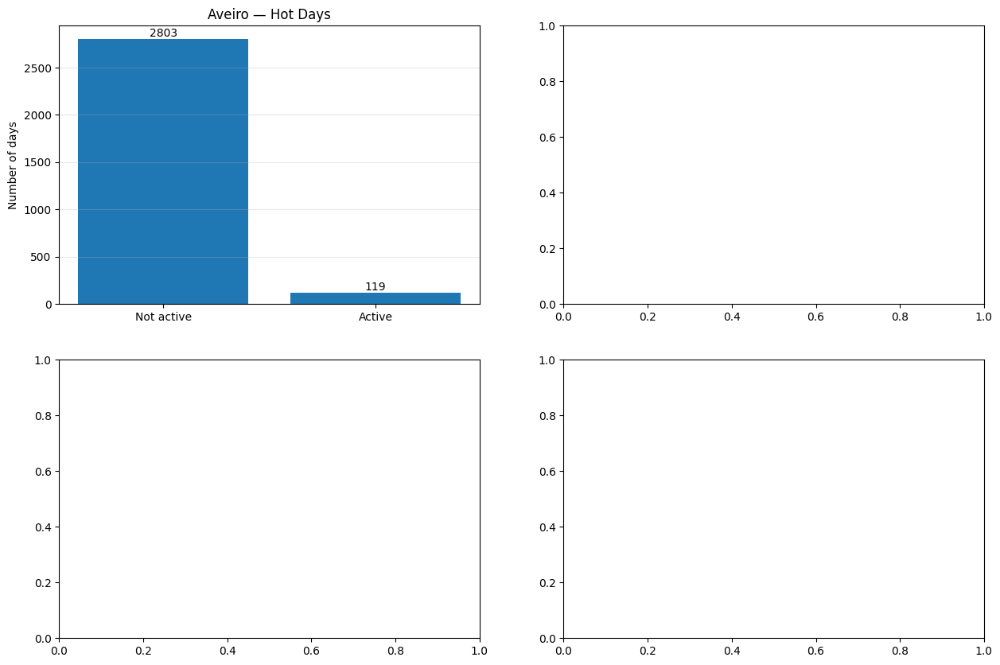

In [11]:
fig, target_summary = plot_target_distribution(
    labeled_data,
    warmup_end=WARMUP_END,
)

display(target_summary.round(2))

In [12]:
for city, df in labeled_data.items():
    plot_heatwave_detection(
        df,
        city,
        threshold=TAU_T_HOT,
        warmup_end=WARMUP_END,
    )

In [13]:
for city, df in clean_data.items():
    plot_calendar_heatmap(
        df=df,
        city=city,
        threshold=TAU_T_HOT,
        years=[2020, 2021, 2022, 2023],
    )

In [14]:



for city, lab_df in labeled_data.items():
    plot_event_comparison(
        weather_df=weather_data[city],
        labeled_df=lab_df,
        city=city,
        variables=["relative_humidity", "precipitation", "wind_speed"],
        warmup_end=globals().get("WARMUP_END"),   # excludes the warm-up period
    )

### Create past-only features

The classifier predicts the current alert state using previous weather measurements. The current temperature is deliberately excluded from the features because it contributes to the detector state and could otherwise reveal the target too directly.

Representation A uses four lagged variables. Representation B adds historical temperature trends and variability.

In [15]:
stream_data = {
    city: prepare_stream_features(df, TAU_T_HOT)
    for city, df in labeled_data.items()
}

for city, df in stream_data.items():
    print(f"{city}: {len(df):,} usable stream observations")
    print(f"Alert prevalence: {df['target_hot'].mean():.2%}")

Aveiro: 70,104 usable stream observations
Alert prevalence: 15.64%
Viseu: 70,104 usable stream observations
Alert prevalence: 20.67%


In [27]:
# Export for the modeling notebook:
#   preproc_<city>.csv  -> FULL timeline (warm-up + evaluation) with a `period` column
#   stream_<city>.csv   -> past-only features + target_hot (evaluation rows only)
import json

PREPROCESSED_DIR.mkdir(parents=True, exist_ok=True)
warmup_cutoff = WARMUP_END + pd.Timedelta(days=1)   # includes the whole warm-up end date

for city_name in clean_data:
    # ---------- 1. full timeline: warm-up + evaluation ----------
    full = clean_data[city_name].copy()
    full["time"] = pd.to_datetime(full["time"])
    full = full.sort_values("time").reset_index(drop=True)

    full["period"] = np.where(full["time"] < warmup_cutoff, "warmup", "evaluation")

    # target_hot exactly as produced by the labeler (NaN where it is not defined, e.g. warm-up)
    lab = labeled_data[city_name][["time", "target_hot"]].copy()
    lab["time"] = pd.to_datetime(lab["time"])
    full = full.merge(lab, on="time", how="left")

    n_warm = int((full["period"] == "warmup").sum())
    n_eval = int((full["period"] == "evaluation").sum())
    assert n_warm + n_eval == len(clean_data[city_name]), f"{city_name}: rows lost in merge"
    assert full["time"].is_unique, f"{city_name}: duplicated timestamps after merge"
    assert full.loc[full["period"] == "evaluation", "target_hot"].notna().all(), (
        f"{city_name}: missing target_hot in the evaluation period"
    )

    full_path = PREPROCESSED_DIR / f"preproc_{city_name.lower()}.csv"
    full.to_csv(full_path, index=False)

    # ---------- 2. stream features (evaluation only) ----------
    stream = stream_data[city_name].copy()
    assert "target_hot" in stream.columns and stream["target_hot"].notna().all()
    stream["target_hot"] = stream["target_hot"].astype(int)
    stream_path = PREPROCESSED_DIR / f"stream_{city_name.lower()}.csv"
    stream.to_csv(stream_path, index=False)

    # ---------- 3. read back and verify ----------
    for path, expected in [(full_path, full), (stream_path, stream)]:
        back = pd.read_csv(path, parse_dates=["time"])
        assert back.shape == expected.shape, f"{path.name}: shape changed on re-read"

    print(
        f"{city_name}: {full_path.name} -> {len(full):,} rows "
        f"({n_warm:,} warm-up + {n_eval:,} evaluation) | "
        f"{stream_path.name} -> {len(stream):,} rows x {stream.shape[1]} cols"
    )

meta = {
    "tau_t_hot": float(TAU_T_HOT),
    "warmup_start": str(WARMUP_START.date()),
    "warmup_end": str(WARMUP_END.date()),
    "hot_percentile": HOT_PERCENTILE,
    "stream_columns": {c: list(d.columns) for c, d in stream_data.items()},
}
with open(PREPROCESSED_DIR / "preproc_meta.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, indent=2)
print("Saved metadata ->", PREPROCESSED_DIR / "preproc_meta.json")

Aveiro: preproc_aveiro.csv -> 96,408 rows (26,280 warm-up + 70,128 evaluation) | stream_aveiro.csv -> 70,104 rows x 18 cols
Viseu: preproc_viseu.csv -> 96,408 rows (26,280 warm-up + 70,128 evaluation) | stream_viseu.csv -> 70,104 rows x 18 cols
Saved metadata -> C:\Users\Rafael\Documents\GitHub\DSM_Practical_Assignment_I\data\preprocessed\preproc_meta.json
